
# Machine Learning Model Training

## Project
Explainable Machine Learning for Chronic Kidney Disease Prediction

## Objective
Predict whether a patient will experience at least a 40% decline
in eGFR at Week 52 using baseline information.

## Models
1. Logistic Regression
2. Random Forest
3. XGBoost



In [38]:

import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path(
    r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES"
)

data_path = project_dir / "datasets" / "processed" / "ckd_model_ready.csv"

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nTarget Distribution:")
print(df["ckd_progression"].value_counts())


Dataset Shape: (4362, 8)


,patient_id,baseline_egfr,treatment_group,baseline_glp1,ckd_progression,egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2,egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2,egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2
0,id0001,54,0,0,0,0,1,0
1,id0003,50,1,0,0,0,1,0
2,id0004,47,0,0,0,0,1,0
3,id0005,75,0,0,0,0,0,1
4,id0006,30,0,0,0,1,0,0



Column Names:
['patient_id', 'baseline_egfr', 'treatment_group', 'baseline_glp1', 'ckd_progression', 'egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2', 'egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2', 'egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2']

Target Distribution:
ckd_progression
0    3892
1     470
Name: count, dtype: int64


In [39]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Patients:")
print(df["patient_id"].duplicated().sum())

print("\nData Types:")
print(df.dtypes)


Missing Values:
patient_id                                              0
baseline_egfr                                           0
treatment_group                                         0
baseline_glp1                                           0
ckd_progression                                         0
egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2    0
egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2    0
egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2    0
dtype: int64

Duplicate Patients:
0

Data Types:
patient_id                                              object
baseline_egfr                                            int64
treatment_group                                          int64
baseline_glp1                                            int64
ckd_progression                                          int64
egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2     int64
egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2     int64
egfr_category_Screening eGFR 6

In [40]:

# Separate features and target

X = df.drop(columns=["patient_id", "ckd_progression"])

y = df["ckd_progression"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (4362, 6)
Target shape: (4362,)

Feature columns:
['baseline_egfr', 'treatment_group', 'baseline_glp1', 'egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2', 'egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2', 'egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2']

Target distribution:
ckd_progression
0    3892
1     470
Name: count, dtype: int64


In [41]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (3489, 6)
Testing features: (873, 6)

Training target distribution:
ckd_progression
0    3113
1     376
Name: count, dtype: int64

Testing target distribution:
ckd_progression
0    779
1     94
Name: count, dtype: int64


In [42]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to test data
X_test_scaled = scaler.transform(X_test)

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)


Training scaled shape: (3489, 6)
Testing scaled shape: (873, 6)


In [43]:

from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression trained successfully!")
print("\nFirst 10 predictions:")
print(y_pred_lr[:10])


Logistic Regression trained successfully!

First 10 predictions:
[0 1 0 0 0 0 0 1 0 0]


In [44]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_lr), 4
))

print("Precision:", round(
    precision_score(y_test, y_pred_lr, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_lr, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_pred_lr, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


Accuracy: 0.8488
Precision: 0.4087
Recall: 0.9043
F1 Score: 0.5629

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.84      0.91       779
           1       0.41      0.90      0.56        94

    accuracy                           0.85       873
   macro avg       0.70      0.87      0.74       873
weighted avg       0.92      0.85      0.87       873


Confusion Matrix:
[[656 123]
 [  9  85]]


In [45]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest trained successfully!")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest trained successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.85      0.92       779
           1       0.43      0.90      0.58        94

    accuracy                           0.86       873
   macro avg       0.71      0.88      0.75       873
weighted avg       0.93      0.86      0.88       873


Confusion Matrix:
[[666 113]
 [  9  85]]


In [46]:
# Rename columns containing unsupported characters
X_train.columns = (
    X_train.columns
    .str.replace("<", "lt", regex=False)
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
)

# Apply the exact same column names to test data
X_test.columns = X_train.columns

print(X_train.columns.tolist())

['baseline_egfr', 'treatment_group', 'baseline_glp1', 'egfr_category_Screening eGFR 30 to lt45 mL/min/1.73m2', 'egfr_category_Screening eGFR 45 to lt60 mL/min/1.73m2', 'egfr_category_Screening eGFR 60 to lt90 mL/min/1.73m2']


In [47]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [48]:

from xgboost import XGBClassifier

# Handle class imbalance
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="logloss"
)

# Train model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost trained successfully!")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_xgb, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBoost trained successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.89       779
           1       0.38      0.94      0.54        94

    accuracy                           0.83       873
   macro avg       0.68      0.88      0.72       873
weighted avg       0.92      0.83      0.86       873


Confusion Matrix:
[[635 144]
 [  6  88]]


In [49]:

# Compare model performance

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8488,0.4087,0.9043,0.5629
1,Random Forest,0.8603,0.4293,0.9043,0.5822
2,XGBoost,0.8282,0.3793,0.9362,0.5399


In [51]:

from sklearn.metrics import roc_auc_score

# Logistic Regression uses scaled numerical data
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Restore the original names used when Random Forest was trained
X_test_rf = X_test.copy()
X_test_rf.columns = rf_model.feature_names_in_

# Random Forest probabilities
rf_prob = rf_model.predict_proba(X_test_rf)[:, 1]

# XGBoost uses the renamed column names
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, lr_prob), 4))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_prob), 4))

print("XGBoost ROC-AUC:",
      round(roc_auc_score(y_test, xgb_prob), 4))


Logistic Regression ROC-AUC: 0.9436
Random Forest ROC-AUC: 0.932
XGBoost ROC-AUC: 0.9459



## Model Performance Visualization

In this section, we compare Logistic Regression, Random Forest,
and XGBoost using visualization techniques.

Charts:
1. Model performance comparison
2. Confusion matrices
3. ROC curves
4. Precision-Recall curves
5. Feature importance (Notebook 05)


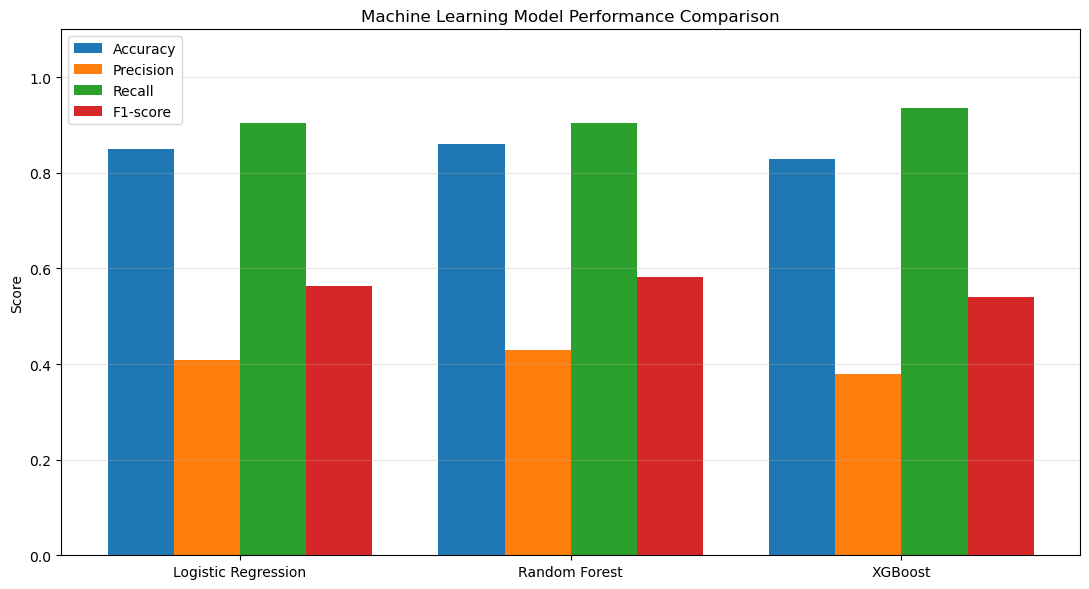

In [52]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Use the model comparison DataFrame already created
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

x = np.arange(len(results["Model"]))
width = 0.2

plt.figure(figsize=(11, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + i * width,
        results[metric],
        width,
        label=metric
    )

plt.xticks(
    x + 1.5 * width,
    results["Model"]
)

plt.ylabel("Score")
plt.title("Machine Learning Model Performance Comparison")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


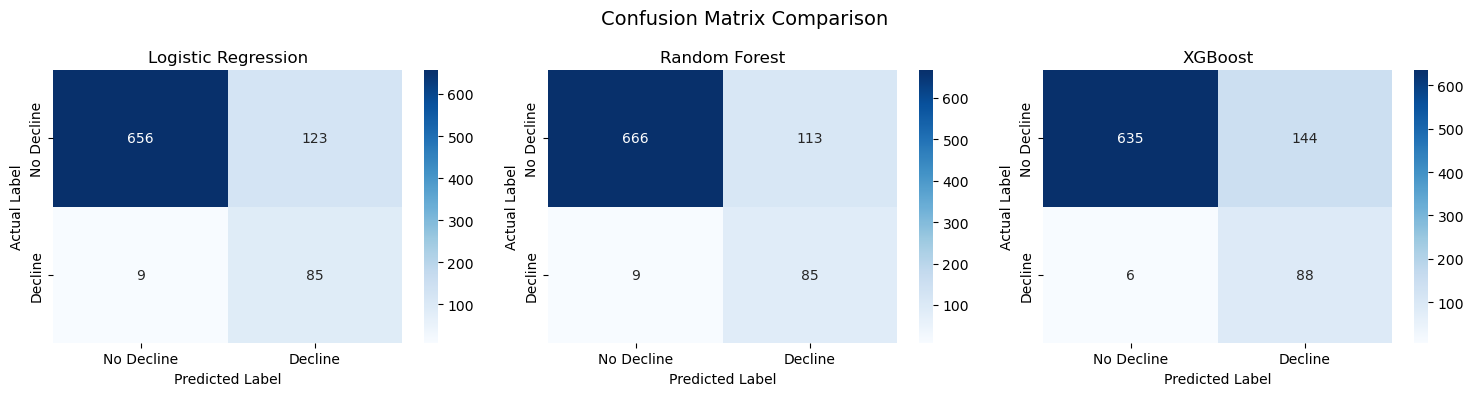

In [53]:

from sklearn.metrics import confusion_matrix

models_predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Decline", "Decline"],
        yticklabels=["No Decline", "Decline"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix Comparison", fontsize=14)
plt.tight_layout()
plt.show()


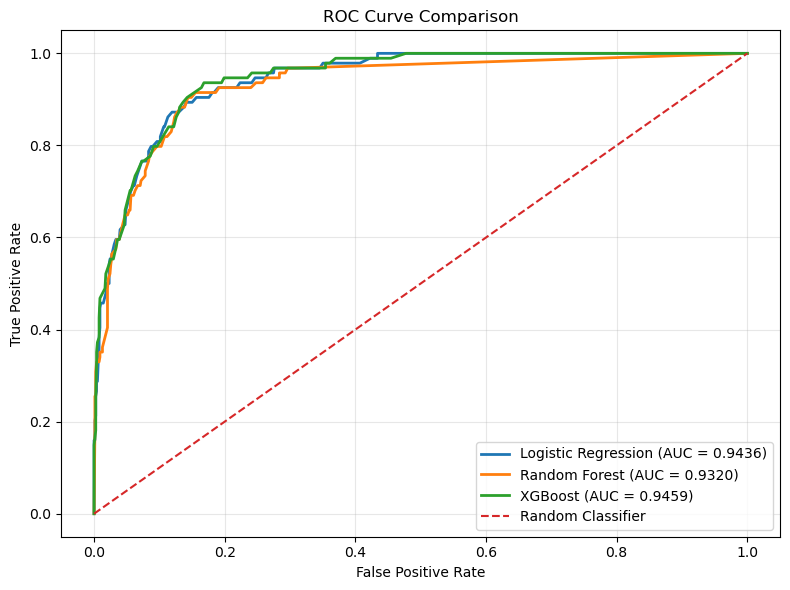

In [54]:

from sklearn.metrics import roc_curve, roc_auc_score

# Uses lr_prob, rf_prob and xgb_prob from your ROC-AUC cell
model_probabilities = {
    "Logistic Regression": lr_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(
        y_test, probabilities
    )

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


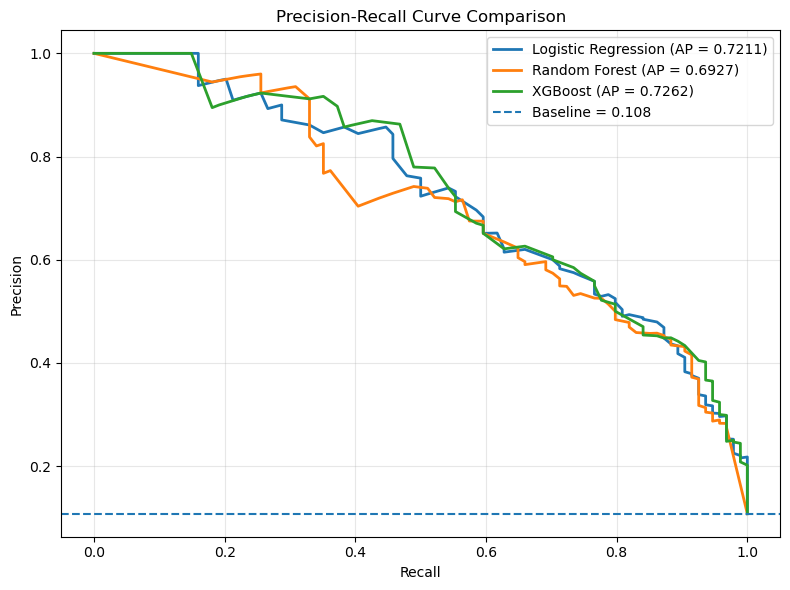

In [55]:

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(
        y_test, probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

# Baseline precision = proportion of positive cases
baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
